In [2]:
# 1-2. Wczytanie danych (sciezki niezalezne od komputera)
from pathlib import Path
import json
import requests
import geopandas as gpd
import pandas as pd

NAZWA_TRZESIENIA = "trzesienia_2025.geojson"
NAZWA_PANSTWA = "ne_110m_admin_0_countries.zip"

# Szukamy folderu z danymi wzgledem miejsca, w ktorym jest notatnik:
# najpierw w biezacym katalogu, potem w katalogach nadrzednych (az do glownego folderu repo).
# Dzieki temu notatnik dziala u kazdego, niezaleznie od tego, gdzie sklonowal repozytorium.
TUTAJ = Path.cwd()
DANE = None
for katalog in [TUTAJ, *TUTAJ.parents]:
    for kandydat in [katalog, katalog / "6", katalog / "data"]:
        if (kandydat / NAZWA_TRZESIENIA).exists():
            DANE = kandydat
            break
    if DANE:
        break

if DANE is None:
    # nie znaleziono danych -> tworzymy folder 6/ obok notatnika i pobierzemy dane z internetu
    DANE = TUTAJ / "6"
    DANE.mkdir(exist_ok=True)

print("Folder z danymi:", DANE)

SCIEZKA_TRZESIENIA = DANE / NAZWA_TRZESIENIA
SCIEZKA_PANSTWA = DANE / NAZWA_PANSTWA

# --- Trzesienia ziemi (USGS) ---
url = "https://earthquake.usgs.gov/fdsnws/event/1/query"

# okres 1 roku, Europa i morze srodziemne, m>=3
parametry = {
    "format": "geojson",
    "starttime": "2025-01-01",
    "endtime": "2026-01-01",
    "minmagnitude": 3.0,
    "minlatitude": 30.0,   # poludnie (M. Śródziemne)
    "maxlatitude": 72.0,   # polnoc (Skandynawia)
    "minlongitude": -25.0, # zachod (Islandia)
    "maxlongitude": 45.0   # wschod (Kaukaz)
}

if SCIEZKA_TRZESIENIA.exists():
    # plik jest w repo -> wczytujemy go, bez laczenia z USGS
    print("Wczytuję dane z pliku:", SCIEZKA_TRZESIENIA)
    dane_json = json.loads(SCIEZKA_TRZESIENIA.read_text(encoding="utf-8"))
else:
    # nie ma pliku -> pobieramy z USGS i zapisujemy
    print("Brak pliku, łączę z USGS...")
    odpowiedz = requests.get(url, params=parametry, timeout=60)
    odpowiedz.raise_for_status()   # jesli USGS zwroci blad, od razu to zobaczymy
    dane_json = odpowiedz.json()
    SCIEZKA_TRZESIENIA.write_text(json.dumps(dane_json), encoding="utf-8")
    print("Zapisano:", SCIEZKA_TRZESIENIA)

gdf = gpd.GeoDataFrame.from_features(dane_json["features"], crs="EPSG:4326")  # WGS 84

# --- Granice panstw (Natural Earth) ---
if not SCIEZKA_PANSTWA.exists():
    print("Brak granic państw, pobieram z Natural Earth...")
    zip_url = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
    odp = requests.get(zip_url, timeout=60, headers={"User-Agent": "Mozilla/5.0"})
    odp.raise_for_status()
    SCIEZKA_PANSTWA.write_bytes(odp.content)
    print("Zapisano:", SCIEZKA_PANSTWA)

print("Pobrano wierszy:", len(gdf))
print(gdf.head(3)) # pierwsze 3 trzesienia

Folder z danymi: D:\Biblioteki_python_6\6
Wczytuję dane z pliku: D:\Biblioteki_python_6\6\trzesienia_2025.geojson
Pobrano wierszy: 804
                           geometry  mag                             place  \
0      POINT Z (35.3086 35.5299 10)  4.4         43 km W of Latakia, Syria   
1  POINT Z (28.4808 36.0705 44.648)  4.2  36 km ESE of Archángelos, Greece   
2      POINT Z (-5.5488 34.0687 10)  4.1        19 km N of Meknès, Morocco   

            time        updated    tz  \
0  1767107131518  1775083721040  None   
1  1767027606759  1775083715040  None   
2  1766616206824  1775083734040  None   

                                                 url  \
0  https://earthquake.usgs.gov/earthquakes/eventp...   
1  https://earthquake.usgs.gov/earthquakes/eventp...   
2  https://earthquake.usgs.gov/earthquakes/eventp...   

                                              detail  felt  cdi  ...  \
0  https://earthquake.usgs.gov/fdsnws/event/1/que...   2.0  2.0  ...   
1  https://earthqu

In [3]:
# wspolrzedna z, szerokosc i dlugosc geo
gdf["depth_km"] = gdf.geometry.z
gdf["longitude"] = gdf.geometry.x
gdf["latitude"] = gdf.geometry.y

In [4]:
print(f"liczba zdarzen: {len(gdf)}")
print("\nuklad wspolrzednych (CRS):", gdf.crs)
print("\ntypy geometrii:\n", gdf.geom_type.value_counts())
print("\npola magnitudy, glebokosci i czasu:", gdf[["mag","depth_km","time"]].head())
print("\nstatystyki opisowe:\n", gdf[["mag","depth_km"]].describe())
print("\nbraki danych", gdf[["mag","depth_km","time"]].isna().sum())

liczba zdarzen: 804

uklad wspolrzednych (CRS): EPSG:4326

typy geometrii:
 Point    804
Name: count, dtype: int64

pola magnitudy, glebokosci i czasu:    mag  depth_km           time
0  4.4    10.000  1767107131518
1  4.2    44.648  1767027606759
2  4.1    10.000  1766616206824
3  4.2   146.758  1766437760250
4  4.0    10.000  1766272436133

statystyki opisowe:
               mag    depth_km
count  804.000000  804.000000
mean     4.331468   18.070448
std      0.361148   28.163457
min      3.000000    0.000000
25%      4.100000   10.000000
50%      4.300000   10.000000
75%      4.500000   10.000000
max      6.500000  404.050000

braki danych mag         0
depth_km    0
time        0
dtype: int64


In [5]:
#4
gdf["datetime"] = pd.to_datetime(gdf["time"], unit="ms", utc=True)

gdf_czyste =gdf[
    gdf["geometry"].notna() &
    gdf.geometry.is_valid &
    (~gdf["geometry"].is_empty) &
    gdf["mag"].notna()
].copy()

print(f"poprawne zdarzenia: {len(gdf_czyste)}")
print(gdf_czyste[["datetime","mag","depth_km","place"]].head())

poprawne zdarzenia: 804
                       datetime  mag  depth_km  \
0 2025-12-30 15:05:31.518+00:00  4.4    10.000   
1 2025-12-29 17:00:06.759+00:00  4.2    44.648   
2 2025-12-24 22:43:26.824+00:00  4.1    10.000   
3 2025-12-22 21:09:20.250+00:00  4.2   146.758   
4 2025-12-20 23:13:56.133+00:00  4.0    10.000   

                              place  
0         43 km W of Latakia, Syria  
1  36 km ESE of Archángelos, Greece  
2        19 km N of Meknès, Morocco  
3        5 km SE of Kéfalos, Greece  
4      12 km WSW of Amorgós, Greece  


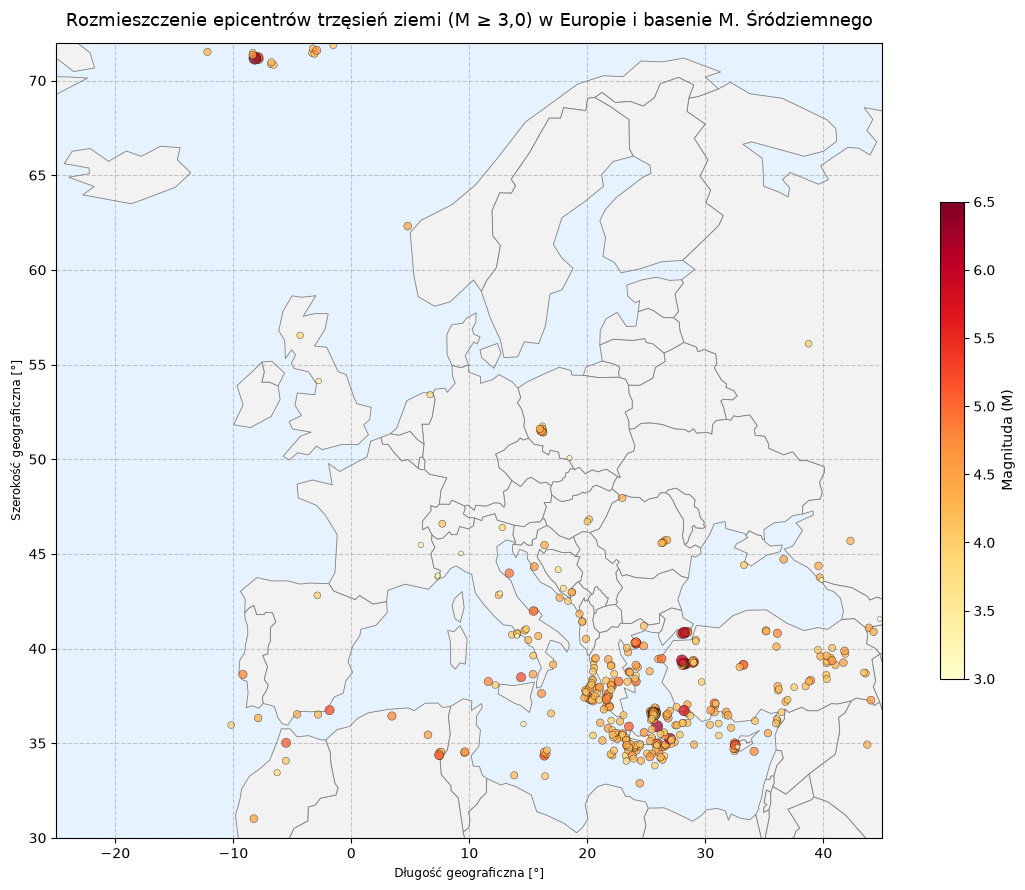

In [6]:
# 5
import matplotlib.pyplot as plt

# sciezka SCIEZKA_PANSTWA ustawiona w pierwszej komorce (folder data/ w repo)
gdf_panstwa = gpd.read_file(SCIEZKA_PANSTWA)

if gdf_panstwa.crs != gdf_czyste.crs:
    gdf_panstwa = gdf_panstwa.to_crs(gdf_czyste.crs)

fig, ax = plt.subplots(figsize=(12, 9))
ax.set_facecolor("#e6f2ff")

gdf_panstwa.plot(
    ax=ax,
    color="#f2f2f2",
    edgecolor="#7f7f7f",
    linewidth=0.6
)


gdf_czyste.plot(
    ax=ax,
    column="mag",
    cmap="YlOrRd",
    markersize=gdf_czyste["mag"] ** 2.3,
    alpha=0.75,
    edgecolor="black",
    linewidth=0.3,
    legend=True,
    legend_kwds={"label": "Magnituda (M)", "shrink": 0.6}
)

ax.set_xlim(-25, 45)
ax.set_ylim(30, 72)

ax.set_title("Rozmieszczenie epicentrów trzęsień ziemi (M ≥ 3,0) w Europie i basenie M. Śródziemnego", fontsize=13, pad=12)
ax.set_xlabel("Długość geograficzna [°]")
ax.set_ylabel("Szerokość geograficzna [°]")
ax.grid(True, linestyle="--", alpha=0.4, color="gray")

plt.tight_layout()
plt.show()


In [7]:
# 6. Przypisanie epicentrow na ladzie do panstw (sjoin), zdarzenia morskie osobno
gdf_sj = gpd.sjoin(
    gdf_czyste,
    gdf_panstwa[["NAME", "geometry"]],
    how="left",          # left = zostaw tez punkty, ktore nie trafily w zadne panstwo
    predicate="within"
)

# punkt na granicy dwoch panstw moglby sie zdublowac - zostawiamy jeden
gdf_sj = gdf_sj[~gdf_sj.index.duplicated(keep="first")]

# brak panstwa = zdarzenie na morzu
gdf_sj["panstwo"] = gdf_sj["NAME"].fillna("Morze")
gdf_sj = gdf_sj.drop(columns=["index_right", "NAME"])

print("Na lądzie:", (gdf_sj["panstwo"] != "Morze").sum())
print("Na morzu:", (gdf_sj["panstwo"] == "Morze").sum())

# Uwaga: warstwa 110m ma uproszczone granice, wiec czesc zdarzen
# tuz przy brzegu moze zostac zakwalifikowana jako "Morze".

Na lądzie: 236
Na morzu: 568


Liczba zdarzeń w poszczególnych obszarach:
panstwo
Morze               568
Turkey              117
Greece               40
Poland               12
Cyprus               10
Italy                10
Romania               6
Algeria               6
Russia                5
Morocco               4
Albania               3
France                3
United Kingdom        2
Armenia               2
Montenegro            2
Hungary               2
Bosnia and Herz.      2
Tunisia               2
Croatia               2
Spain                 1
Iraq                  1
Netherlands           1
Switzerland           1
Georgia               1
Portugal              1
Name: count, dtype: int64

TOP 10 obszarów:
panstwo
Morze      568
Turkey     117
Greece      40
Poland      12
Cyprus      10
Italy       10
Romania      6
Algeria      6
Russia       5
Morocco      4
Name: count, dtype: int64


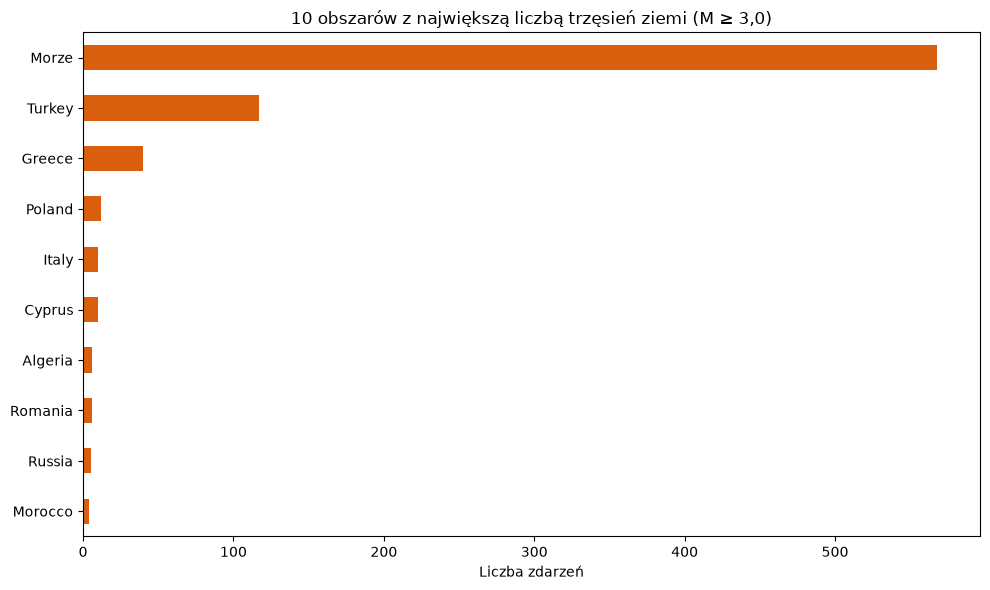

In [8]:
# 7. Liczba zdarzen w panstwach i 10 obszarow z najwieksza liczba zdarzen
liczba_zdarzen = gdf_sj["panstwo"].value_counts()
print("Liczba zdarzeń w poszczególnych obszarach:")
print(liczba_zdarzen)

top10 = liczba_zdarzen.head(10)
print("\nTOP 10 obszarów:")
print(top10)

fig, ax = plt.subplots(figsize=(10, 6))
top10.sort_values().plot(kind="barh", ax=ax, color="#d95f0e")
ax.set_title("10 obszarów z największą liczbą trzęsień ziemi (M ≥ 3,0)")
ax.set_xlabel("Liczba zdarzeń")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Zdarzenia M >= 3,0: 804
Zdarzenia M >= 5,0: 40 (5.0% wszystkich)

Najwięcej zdarzeń M >= 5,0:
panstwo
Morze      25
Turkey      9
Cyprus      2
Greece      2
Algeria     1
Morocco     1
Name: count, dtype: int64


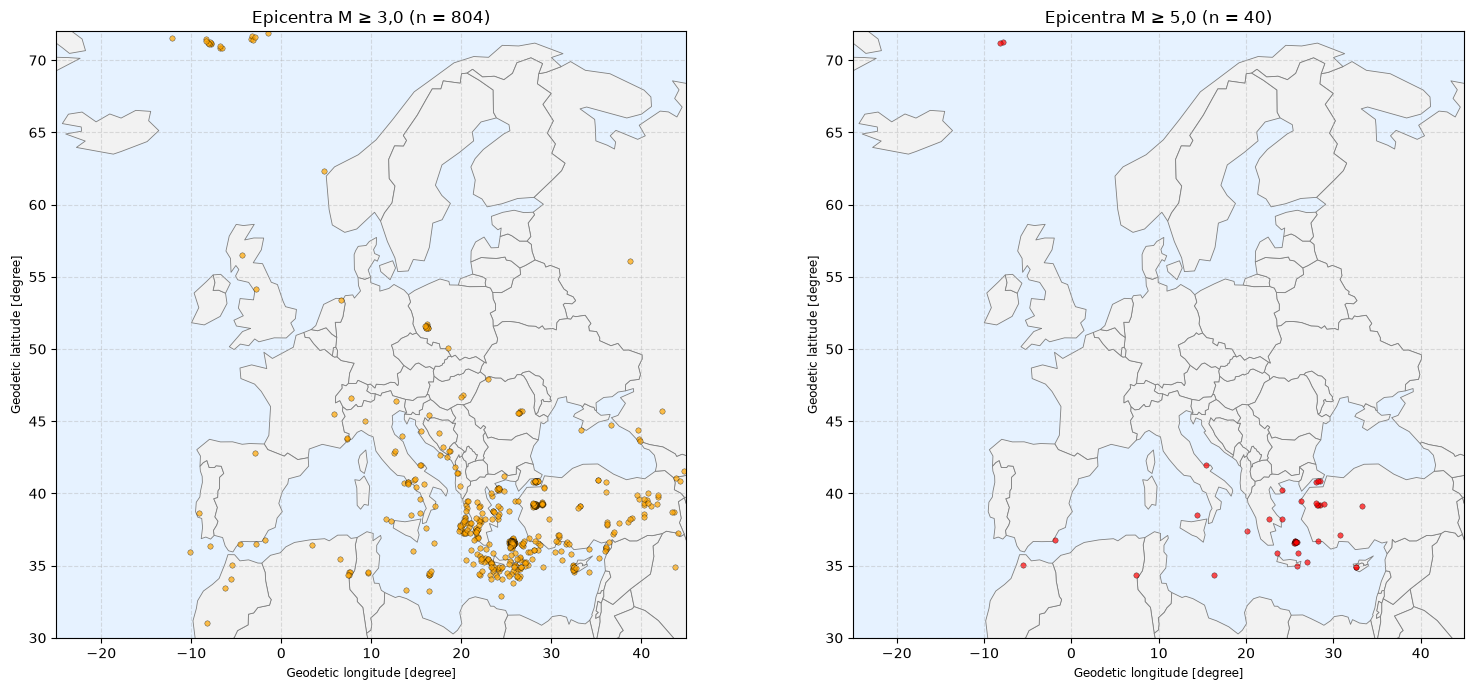

In [9]:
# 8. Porownanie rozmieszczenia epicentrow M >= 3,0 i M >= 5,0
m3 = gdf_sj[gdf_sj["mag"] >= 3.0]
m5 = gdf_sj[gdf_sj["mag"] >= 5.0]

print(f"Zdarzenia M >= 3,0: {len(m3)}")
print(f"Zdarzenia M >= 5,0: {len(m5)} ({len(m5) / len(m3) * 100:.1f}% wszystkich)")

print("\nNajwięcej zdarzeń M >= 5,0:")
print(m5["panstwo"].value_counts().head(10))

# dwie mapy obok siebie
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, dane, tytul, kolor in [
    (axes[0], m3, "M ≥ 3,0", "orange"),
    (axes[1], m5, "M ≥ 5,0", "red"),
]:
    ax.set_facecolor("#e6f2ff")
    gdf_panstwa.plot(ax=ax, color="#f2f2f2", edgecolor="#7f7f7f", linewidth=0.6)
    dane.plot(ax=ax, color=kolor, markersize=15, alpha=0.7, edgecolor="black", linewidth=0.3)
    ax.set_xlim(-25, 45)
    ax.set_ylim(30, 72)
    ax.set_title(f"Epicentra {tytul} (n = {len(dane)})")
    ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# Wniosek: slabsze trzesienia (M >= 3) wystepuja w calym pasie od Islandii,
# przez Wlochy i Balkany, po Turcje. Silniejsze (M >= 5) skupiaja sie
# glownie w Grecji, Turcji i na Morzu Egejskim - tam gdzie stykaja sie plyty tektoniczne.

In [10]:
# 9. Srednia, mediana i maksimum magnitudy oraz glebokosci
statystyki = gdf_sj[["mag", "depth_km"]].agg(["mean", "median", "max"]).round(2)
statystyki.index = ["średnia", "mediana", "maksimum"]
statystyki.columns = ["magnituda [M]", "głębokość [km]"]
print(statystyki)

# Uwaga: mediana glebokosci = 10 km, bo USGS dla wielu slabszych zdarzen
# przyjmuje glebokosc "na sztywno" 10 km, gdy nie da sie jej dokladnie wyznaczyc.
print("\nZdarzenia z głębokością dokładnie 10 km:", (gdf_sj["depth_km"] == 10).sum())

          magnituda [M]  głębokość [km]
średnia            4.33           18.07
mediana            4.30           10.00
maksimum           6.50          404.05

Zdarzenia z głębokością dokładnie 10 km: 582


                       liczba  srednia_mag  max_mag  udzial_%
grupa_glebokosci                                             
płytkie (0–70 km)         781         4.33      6.5      97.1
pośrednie (70–300 km)      21         4.48      6.0       2.6
głębokie (>300 km)          2         4.20      4.3       0.2


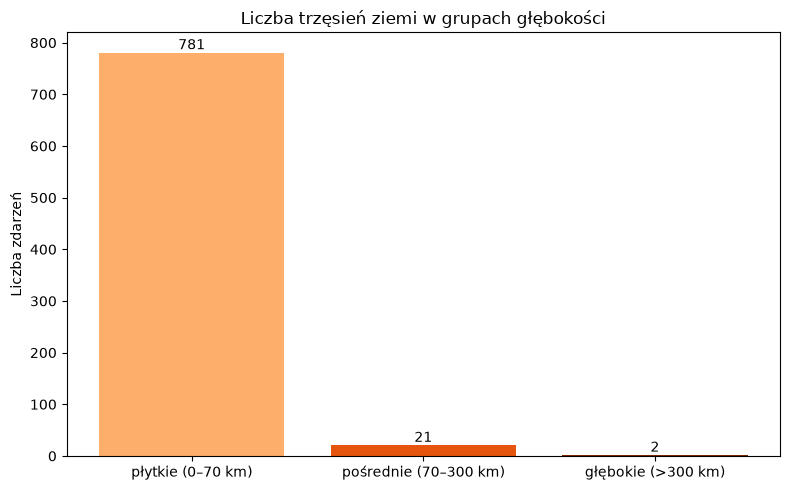

In [11]:
# 10. Podzial na trzy grupy glebokosci
# klasyczny podzial sejsmologiczny:
#   plytkie   0 - 70 km
#   posrednie 70 - 300 km
#   glebokie  > 300 km
przedzialy = [0, 70, 300, float("inf")]
etykiety = ["płytkie (0–70 km)", "pośrednie (70–300 km)", "głębokie (>300 km)"]

gdf_sj["grupa_glebokosci"] = pd.cut(
    gdf_sj["depth_km"],
    bins=przedzialy,
    labels=etykiety,
    include_lowest=True  # zeby glebokosc 0 km tez wpadla do "plytkich"
)

grupy = gdf_sj.groupby("grupa_glebokosci", observed=False).agg(
    liczba=("mag", "size"),
    srednia_mag=("mag", "mean"),
    max_mag=("mag", "max")
)
grupy["udzial_%"] = (grupy["liczba"] / grupy["liczba"].sum() * 100).round(1)
print(grupy.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(grupy.index.astype(str), grupy["liczba"], color=["#fdae6b", "#e6550d", "#7f2704"])
for i, v in enumerate(grupy["liczba"]):
    ax.text(i, v, str(v), ha="center", va="bottom")
ax.set_title("Liczba trzęsień ziemi w grupach głębokości")
ax.set_ylabel("Liczba zdarzeń")
plt.tight_layout()
plt.show()

# Wniosek: zdecydowana wiekszosc trzesien to zdarzenia plytkie (skorupa ziemska).
# Posrednie i glebokie wystepuja glownie tam, gdzie plyta afrykanska wchodzi pod euroazjatycka
# (luk Helenski - Grecja/Kreta, Morze Tyrrenskie - poludniowe Wlochy).

In [ ]:
# 11. Wykres rozrzutu: magnituda wzgledem glebokosci
pearson = gdf_sj["mag"].corr(gdf_sj["depth_km"])
# Spearman = korelacja na rangach (odporna na wartosci odstajace)
spearman = gdf_sj["mag"].rank().corr(gdf_sj["depth_km"].rank())

# bez zdarzen z glebokoscia "na sztywno" 10 km (patrz punkt 9)
bez_10 = gdf_sj[gdf_sj["depth_km"] != 10]
pearson_bez_10 = bez_10["mag"].corr(bez_10["depth_km"])

print(f"Korelacja Pearsona:  {pearson:.3f}")
print(f"Korelacja Spearmana: {spearman:.3f}")
print(f"Pearson bez głębokości 10 km (n = {len(bez_10)}): {pearson_bez_10:.3f}")

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(
    gdf_sj["depth_km"], gdf_sj["mag"],
    c=gdf_sj["mag"], cmap="YlOrRd",
    s=25, alpha=0.7, edgecolor="black", linewidth=0.3
)
ax.set_xlabel("Głębokość [km]")
ax.set_ylabel("Magnituda [M]")
ax.set_title(f"Magnituda a głębokość trzęsień ziemi (r Pearsona = {pearson:.2f})")
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# Interpretacja: korelacja wychodzi praktycznie zerowa (r ok. 0), takze po usunieciu zdarzen
# z glebokoscia 10 km. Glebokosc nie mowi nic o magnitudzie - silne trzesienia zdarzaja sie
# zarowno plytko, jak i glebiej. Wiekszosc punktow tworzy pionowa "kolumne" na 10 km -
# to glebokosc przyjeta przez USGS, a nie zmierzona.

In [ ]:
# 12. Dziesiec zdarzen o najwiekszej magnitudzie
top10_mag = gdf_sj.nlargest(10, "mag")[["datetime", "mag", "magType", "depth_km", "place", "panstwo"]].copy()
top10_mag["datetime"] = top10_mag["datetime"].dt.strftime("%Y-%m-%d %H:%M")
top10_mag["depth_km"] = top10_mag["depth_km"].round(1)
top10_mag.columns = ["data (UTC)", "magnituda", "typ magnitudy", "głębokość [km]", "miejsce", "państwo / morze"]
top10_mag.index = range(1, 11)

print(top10_mag.to_string())

In [ ]:
# 13. Miesieczna liczba zdarzen i rozklad aktywnosci w czasie
# usuwamy strefe czasowa (UTC), bo to_period() jej nie obsluguje
miesiac = gdf_sj["datetime"].dt.tz_localize(None).dt.to_period("M")

wszystkie_miesiace = pd.period_range("2025-01", "2025-12", freq="M")
miesieczne = miesiac.value_counts().reindex(wszystkie_miesiace, fill_value=0)
miesieczne_m5 = miesiac[gdf_sj["mag"] >= 5.0].value_counts().reindex(wszystkie_miesiace, fill_value=0)

tabela_miesiace = pd.DataFrame({"M >= 3,0": miesieczne, "M >= 5,0": miesieczne_m5})
print(tabela_miesiace)

print(f"\nŚrednio zdarzeń na miesiąc: {miesieczne.mean():.1f}")
print(f"Mediana miesięczna: {miesieczne.median():.1f}")
print(f"Najwięcej: {miesieczne.idxmax()} ({miesieczne.max()} zdarzeń)")
print(f"Najmniej: {miesieczne.idxmin()} ({miesieczne.min()} zdarzeń)")

nazwy = ["sty", "lut", "mar", "kwi", "maj", "cze", "lip", "sie", "wrz", "paź", "lis", "gru"]

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(nazwy, miesieczne.values, color="#fdae6b", label="M ≥ 3,0")
ax.bar(nazwy, miesieczne_m5.values, color="#d7301f", label="w tym M ≥ 5,0")
ax.axhline(miesieczne.mean(), color="black", linestyle="--", linewidth=1, label="średnia miesięczna")
ax.set_title("Miesięczna liczba trzęsień ziemi w 2025 r.")
ax.set_ylabel("Liczba zdarzeń")
ax.legend()
plt.tight_layout()
plt.show()

# Wniosek: aktywnosc nie jest rowna w ciagu roku. Luty 2025 ma kilka razy wiecej zdarzen niz
# pozostale miesiace - to roj trzesien kolo Santorini. Bez niego miesieczna liczba zdarzen jest
# dosc stabilna (ok. 30-60). Skoki wynikaja z pojedynczych serii trzesien, a nie z pory roku,
# dlatego mediana miesieczna lepiej opisuje "typowy" miesiac niz srednia.

In [ ]:
# 14. Siatka 100 x 100 km w EPSG:3035 i liczba epicentrow w kazdej komorce
import numpy as np
from shapely.geometry import box

ROZMIAR = 100_000  # 100 km w metrach (EPSG:3035 ma jednostki w metrach)

gdf_3035 = gdf_sj.to_crs(epsg=3035)

# zasieg siatki zaokraglony do pelnych 100 km
xmin, ymin, xmax, ymax = gdf_3035.total_bounds
xmin = np.floor(xmin / ROZMIAR) * ROZMIAR
ymin = np.floor(ymin / ROZMIAR) * ROZMIAR
xmax = np.ceil(xmax / ROZMIAR) * ROZMIAR
ymax = np.ceil(ymax / ROZMIAR) * ROZMIAR

komorki = [
    box(x, y, x + ROZMIAR, y + ROZMIAR)
    for x in np.arange(xmin, xmax, ROZMIAR)
    for y in np.arange(ymin, ymax, ROZMIAR)
]
siatka = gpd.GeoDataFrame({"id_komorki": range(len(komorki))}, geometry=komorki, crs="EPSG:3035")
print("Liczba komórek siatki:", len(siatka))

# przypisanie epicentrow do komorek
polaczenie = gpd.sjoin(
    gdf_3035[["mag", "place", "geometry"]],
    siatka,
    how="inner",
    predicate="intersects"
)
# punkt lezacy dokladnie na krawedzi trafilby do 2 komorek - liczymy go tylko raz
polaczenie = polaczenie[~polaczenie.index.duplicated(keep="first")]

zliczenia = polaczenie.groupby("id_komorki").agg(
    liczba=("mag", "size"),
    liczba_m5=("mag", lambda s: (s >= 5.0).sum()),
    max_mag=("mag", "max")
)
siatka = siatka.merge(zliczenia, on="id_komorki", how="left")
siatka[["liczba", "liczba_m5"]] = siatka[["liczba", "liczba_m5"]].fillna(0).astype(int)

print("Komórki z co najmniej 1 zdarzeniem:", (siatka["liczba"] > 0).sum())
print("Maksymalna liczba zdarzeń w komórce:", siatka["liczba"].max())
print("Kontrola - suma zdarzeń w siatce:", siatka["liczba"].sum(), "/", len(gdf_3035))

# kartogram siatkowy
# skala logarytmiczna: jedna komorka (Santorini) ma kilkaset zdarzen, reszta kilka-kilkanascie,
# wiec przy zwyklej skali wszystkie pozostale komorki bylyby prawie biale
from matplotlib.colors import LogNorm
skala = LogNorm(vmin=1, vmax=siatka["liczba"].max())

panstwa_3035 = gdf_panstwa.clip(box(-35, 25, 55, 75)).to_crs(epsg=3035)  # tylko Europa, bez reszty swiata

fig, ax = plt.subplots(figsize=(12, 10))
ax.set_facecolor("#e6f2ff")
panstwa_3035.plot(ax=ax, color="#f2f2f2", edgecolor="#7f7f7f", linewidth=0.5)
siatka[siatka["liczba"] > 0].plot(
    ax=ax,
    column="liczba",
    cmap="YlOrRd",
    norm=skala,
    edgecolor="grey",
    linewidth=0.2,
    legend=True,
    legend_kwds={"label": "Liczba epicentrów w komórce (skala log)", "shrink": 0.6}
)
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_title("Liczba epicentrów w komórkach 100 × 100 km (EPSG:3035)")
ax.set_axis_off()
plt.tight_layout()
plt.show()

# Wniosek: zdarzenia skupiaja sie w waskim pasie Grecja - Morze Egejskie - Turcja - Wlochy.
# Wiekszosc Europy (np. Skandynawia, Francja, Niemcy) ma 0 zdarzen M >= 3 w komorkach.

In [ ]:
# 15. Komorki z najwieksza liczba zdarzen a strefy silniejszych trzesien (M >= 5,0)
top_komorki = siatka.nlargest(10, "liczba").copy()

# przyblizony region komorki = najczestszy kraj/obszar w opisie "place" (np. "..., Greece")
polaczenie["region"] = polaczenie["place"].str.split(", ").str[-1]
region_komorki = polaczenie.groupby("id_komorki")["region"].agg(lambda s: s.value_counts().index[0])
top_komorki["region"] = top_komorki["id_komorki"].map(region_komorki)

print("10 komórek z największą liczbą zdarzeń:")
print(top_komorki[["id_komorki", "region", "liczba", "liczba_m5", "max_mag"]].to_string(index=False))

# porownanie ze strefami silnych trzesien
wszystkie_m5 = int(siatka["liczba_m5"].sum())
m5_w_top = int(top_komorki["liczba_m5"].sum())
top_z_m5 = int((top_komorki["liczba_m5"] > 0).sum())
komorki_z_m5 = siatka[siatka["liczba_m5"] > 0]

print(f"\nKomórki z top 10, w których było trzęsienie M >= 5,0: {top_z_m5} z 10")
print(f"Zdarzenia M >= 5,0 w komórkach top 10: {m5_w_top} z {wszystkie_m5} "
      f"({m5_w_top / wszystkie_m5 * 100:.0f}%)")
print(f"Wszystkie komórki z co najmniej jednym M >= 5,0: {len(komorki_z_m5)}")

# mapa: kartogram + obrys komorek top 10 + epicentra M >= 5,0
m5_3035 = gdf_3035[gdf_3035["mag"] >= 5.0]

fig, ax = plt.subplots(figsize=(12, 10))
ax.set_facecolor("#e6f2ff")
panstwa_3035.plot(ax=ax, color="#f2f2f2", edgecolor="#7f7f7f", linewidth=0.5)
siatka[siatka["liczba"] > 0].plot(ax=ax, column="liczba", cmap="YlOrRd", norm=skala, alpha=0.6)
top_komorki.boundary.plot(ax=ax, color="blue", linewidth=2, label="top 10 komórek")
m5_3035.plot(ax=ax, color="black", marker="*", markersize=80, label="epicentra M ≥ 5,0")
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_title("Komórki z największą liczbą zdarzeń a epicentra trzęsień M ≥ 5,0")
ax.legend(loc="upper left")
ax.set_axis_off()
plt.tight_layout()
plt.show()

# Wnioski:
# - Komorka z najwieksza liczba zdarzen (ok. 370) to rejon Santorini-Amorgos (Grecja):
#   w lutym 2025 wystapil tam roj trzesien, ktory sam w sobie daje prawie polowe wszystkich zdarzen.
# - 6 z 10 najaktywniejszych komorek zawiera tez trzesienie M >= 5,0, ale tylko ok. polowa
#   wszystkich silnych trzesien lezy w tych komorkach - silne zdarzenia sa bardziej rozproszone.
# - W top 10 jest komorka w Polsce (Zaglebie Miedziowe, LGOM): to wstrzasy indukowane
#   gornictwem, liczne ale slabe (max M < 5), wiec nie pokrywaja sie ze strefami silnych trzesien.